# PSE Pulse — Final User Acceptance Testing Analysis

**Chapter IV and V research evidence | 16 October 2026 | 8 valid submissions**

This notebook describes the researcher-supplied final questionnaire responses. It reports respondent perceptions, not measured forecasting accuracy or objective performance. The final questionnaire PDF and private Google Forms workbook remain outside this repository.

## 1. Data handling and privacy

The source workbook contains email addresses and timestamps. The analysis reads them only to validate consent and duplicates. This notebook displays aggregate tables and charts. Raw responses, private identifiers, and free-text excerpts are not embedded. Set `PSE_PULSE_UAT_WORKBOOK` to an authorized local XLSX path before rerunning.

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from uat_analysis import run

source = os.environ.get('PSE_PULSE_UAT_WORKBOOK')
if not source:
    raise RuntimeError('Set PSE_PULSE_UAT_WORKBOOK to the private response workbook path')
result = run(Path(source), Path.cwd())
meta, tables = result['meta'], result['tables']
N = meta['valid']
assert N == 8 and len(result['mapping']['fields']) == 56
print(f'Validated {N} consenting unique submissions; 47 rating items; aggregate outputs refreshed.')
PASTEL = ['#A8DADC', '#B8C9F0', '#F4C7D7', '#CDE7BE', '#F8DDA8', '#D9C4E8', '#B7DFD3', '#F6C8A0', '#CBD5E1']
plt.rcParams.update({'figure.figsize': (10, 5.8), 'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.labelcolor':'#334155', 'text.color':'#1e293b'})
def barh(labels, values, title, xlabel, xmax, colors=None, fmt='{:.0f}', height=None):
    fig, ax = plt.subplots(figsize=(11, height or max(4.2, 0.42*len(labels)+1.4)))
    y = np.arange(len(labels))
    ax.barh(y, values, color=colors or [PASTEL[i%len(PASTEL)] for i in range(len(labels))], edgecolor='#64748b', linewidth=.4)
    ax.set_yticks(y, labels); ax.invert_yaxis(); ax.set_xlim(0, xmax)
    ax.set_xlabel(xlabel); ax.set_title(title, pad=15)
    ax.grid(axis='x', alpha=.2); ax.set_axisbelow(True)
    for yi,v in zip(y,values): ax.text(min(v+xmax*.012,xmax*.96), yi, fmt.format(v), va='center', fontsize=9)
    fig.tight_layout(); display(fig); plt.close(fig)
def show_table(df, columns=None):
    view = (df[columns] if columns else df).reset_index(drop=True)
    style = "<style>table.uat-table {border-collapse:collapse;font-size:13px;} table.uat-table th,table.uat-table td {padding:6px 9px;border-bottom:1px solid #d7e1e8;vertical-align:top;white-space:normal;max-width:420px;text-align:left;} table.uat-table th {background:#eaf3f5;color:#243746;}</style>"
    display(HTML(style + '<div style="overflow-x:auto;max-width:100%">' + view.to_html(index=False, escape=True, border=0, classes='uat-table') + '</div>'))


/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Validated 8 consenting unique submissions; 47 rating items; aggregate outputs refreshed.


## 2. Questionnaire structure and provenance

The final PDF has 36 numbered questions. The workbook has 60 columns: four administrative fields, nine profile/qualitative fields, and 47 rating columns (21 Q7–Q27, nine Q28, eight Q29, nine Q33). Every observed rating label is on the corresponding final scale. The workbook has no per-response form-version field, so matching headers and options support compatibility but cannot independently prove which live version each respondent saw. Responses dated before the PDF export are retained.

In [2]:
print('Submission period:', meta['first_timestamp'], 'to', meta['last_timestamp']); print('Missing rating values:', sum(meta['missing'][f['id']] for f in result['mapping']['fields'] if f['scale'])); print('Duplicate email keys:', meta['duplicate_email']); print('Optional Q35 blanks:', meta['missing']['Q35'])

Submission period: 2026-10-13 23:41:08.630000 to 2026-10-16 06:33:15.482000
Missing rating values: 0
Duplicate email keys: 0
Optional Q35 blanks: 8


## 3. Scoring methodology

For each five-point item, 1 is the least favorable and 5 is the most favorable label shown in the final PDF. Favorable means scores 4–5. Tables retain all five category counts and percentages, valid and missing counts, median, sample standard deviation, and mean. Frequencies are primary evidence; means are descriptive summaries of ordinal responses. The middle help rating is **Moderately Helpful**, not a neutral agreement response. No significance tests, composite acceptance score, or unsupported pass/fail threshold are used.

In [3]:
display(pd.DataFrame([{'scale':k,'1':v[0],'2':v[1],'3':v[2],'4':v[3],'5':v[4]} for k,v in result['mapping']['scales_low_to_high'].items()]))

,scale,1,2,3,4,5
0,ease,Very Difficult,Somewhat Difficult,Neither Easy nor Difficult,Somewhat Easy,Very Easy
1,clarity,Very Unclear,Somewhat Unclear,Neither Clear nor Unclear,Somewhat Clear,Very Clear
2,relevance,Very Irrelevant,Somewhat Irrelevant,Neither Relevant nor Irrelevant,Somewhat Relevant,Very Relevant
3,helpfulness,Not Helpful,Slightly Helpful,Moderately Helpful,Very Helpful,Extremely Helpful
4,agreement,Strongly Disagree,Disagree,Neutral,Agree,Strongly Agree


## 4. Respondent profile

Each respondent evaluated desktop/laptop and tablet/mobile use. The form did not ask whether the first device was specifically a desktop or laptop.

In [4]:
show_table(tables['uat_participant_profile.csv'])

item_id,profile,response,count,valid_n,percentage
Q4,Investing experience,Beginner,7,8,87.5
Q4,Investing experience,Intermediate,1,8,12.5
Q5,Desktop/laptop browser,Google Chrome,7,8,87.5
Q5,Desktop/laptop browser,Mozilla Firefox,1,8,12.5
Q6,Desktop/laptop theme,Dark mode,8,8,100.0
Q30,Tablet/mobile device,Mobile Phone,7,8,87.5
Q30,Tablet/mobile device,Tablet,1,8,12.5
Q31,Tablet/mobile browser,Google Chrome,7,8,87.5
Q31,Tablet/mobile browser,Safari,1,8,12.5
Q32,Tablet/mobile theme,Dark mode,8,8,100.0


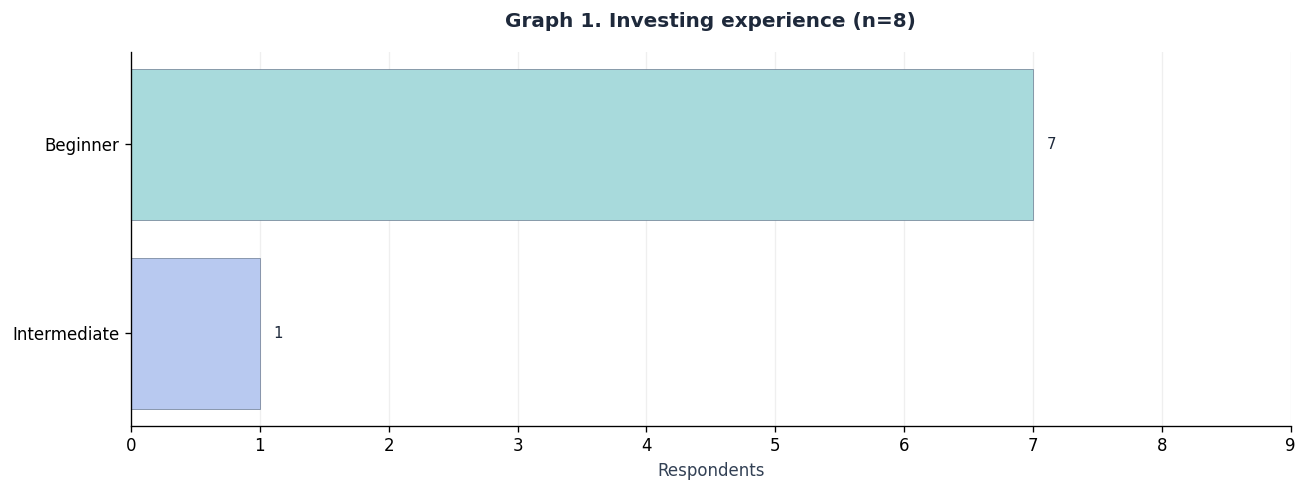

In [5]:
p=tables['uat_participant_profile.csv']; d=p[p.item_id=='Q4']; barh(d.response.tolist(), d['count'].tolist(), 'Graph 1. Investing experience (n=8)', 'Respondents', 9, fmt='{:.0f}')

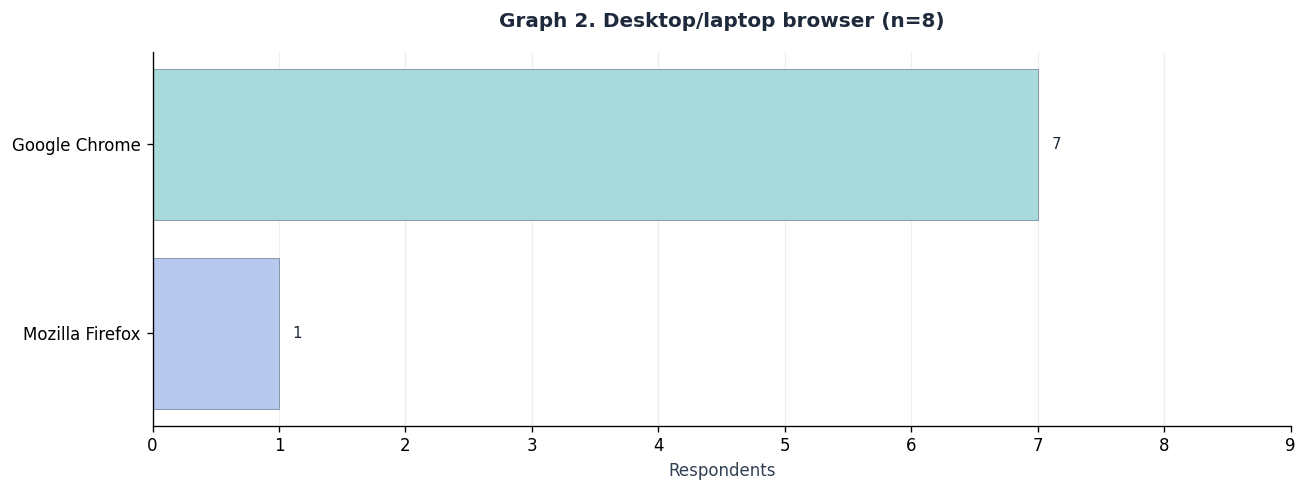

In [6]:
p=tables['uat_participant_profile.csv']; d=p[p.item_id=='Q5']; barh(d.response.tolist(), d['count'].tolist(), 'Graph 2. Desktop/laptop browser (n=8)', 'Respondents', 9, fmt='{:.0f}')

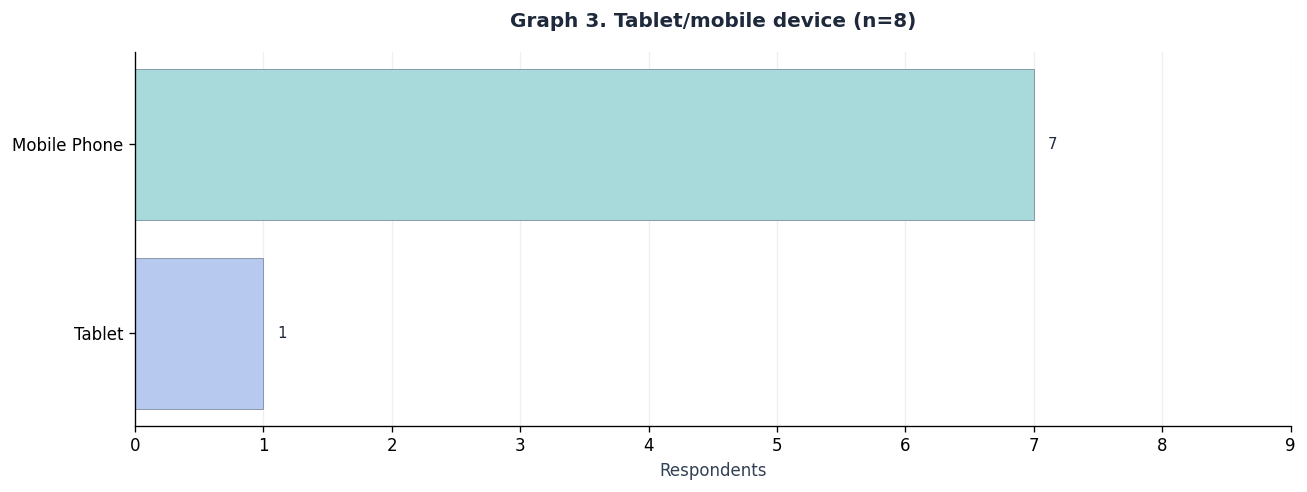

In [7]:
p=tables['uat_participant_profile.csv']; d=p[p.item_id=='Q30']; barh(d.response.tolist(), d['count'].tolist(), 'Graph 3. Tablet/mobile device (n=8)', 'Respondents', 9, fmt='{:.0f}')

**Interpretation.** Seven of eight participants reported beginner experience; seven tested on mobile phones and one on a tablet. All eight preferred dark mode on both device categories. These are sample descriptions, not population estimates.

## 5. Website navigation and usability

In [8]:
d=tables['uat_navigation_usability_summary.csv']; show_table(d,['item_id','area','valid_n','score_1_n','score_2_n','score_3_n','score_4_n','score_5_n','mean','median','sample_sd','favorable_pct'])

item_id,area,valid_n,score_1_n,score_2_n,score_3_n,score_4_n,score_5_n,mean,median,sample_sd,favorable_pct
Q7,Home,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q8,Home,8,0,0,0,0,8,5.000,5.0,0.000,100.0
Q9,Home,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q10,Companies and Company Details,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q11,Companies and Company Details,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q12,Companies and Company Details,8,0,0,0,0,8,5.000,5.0,0.000,100.0
Q13,Companies and Company Details,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q14,My Watchlist,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q15,My Watchlist,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q16,My Watchlist,8,0,0,0,1,7,4.875,5.0,0.354,100.0


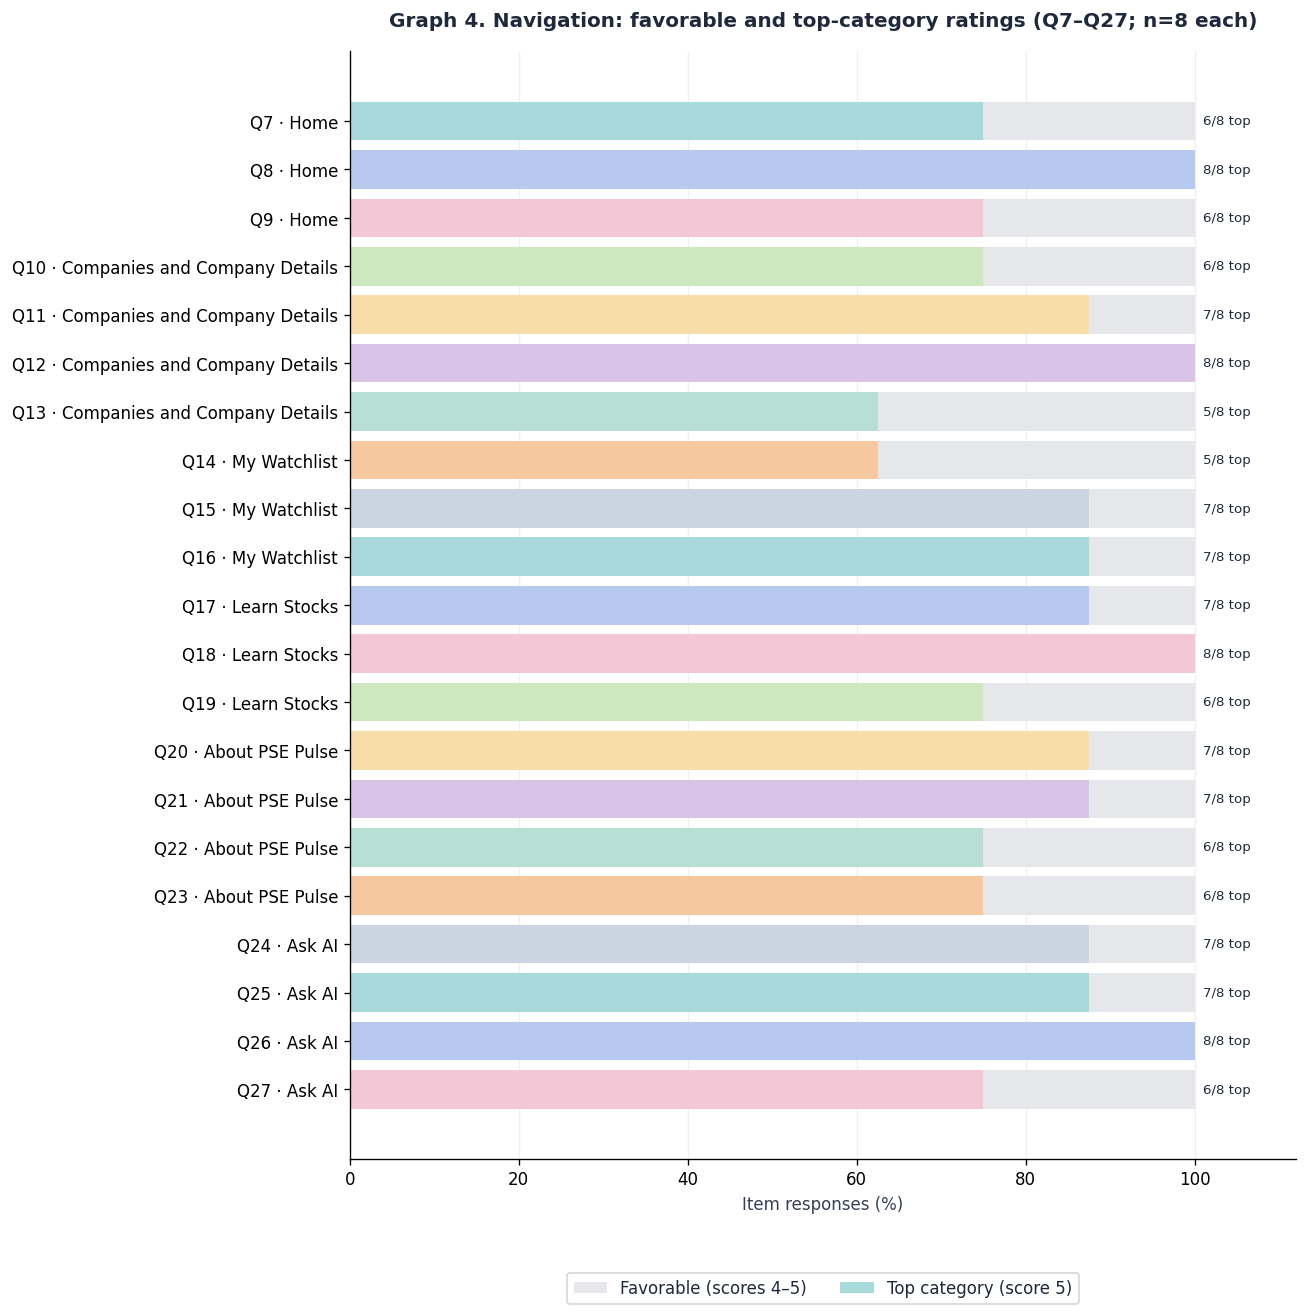

In [9]:
d=tables['uat_navigation_usability_summary.csv']; labels=(d.item_id+' · '+d.area).tolist(); y=np.arange(len(d))
fig,ax=plt.subplots(figsize=(11,11))
ax.barh(y,d.favorable_pct,color='#E5E7EB',label='Favorable (scores 4–5)')
ax.barh(y,100*d.score_5_n/d.valid_n,color=[PASTEL[i%len(PASTEL)] for i in range(len(d))],label='Top category (score 5)')
ax.set_yticks(y,labels); ax.invert_yaxis(); ax.set_xlim(0,112)
ax.set_xlabel('Item responses (%)'); ax.set_title('Graph 4. Navigation: favorable and top-category ratings (Q7–Q27; n=8 each)',pad=15)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.095),ncol=2); ax.grid(axis='x',alpha=.2); ax.set_axisbelow(True)
for yi,top in zip(y,d.score_5_n): ax.text(101,yi,f'{top}/8 top',va='center',fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)

**Interpretation.** All 21 items received 8/8 favorable ratings. Q8, Q12, Q18, and Q26 received 8/8 top-category ratings. Q13 (view toggle) and Q14 (adding to watchlist) had the lowest navigation means (4.625/5 each), with 5 top-category and 3 next-category responses. Favorable perception of forecast-chart clarity does not establish forecast accuracy.

## 6. Feature helpfulness

In [10]:
d=tables['uat_feature_helpfulness_summary.csv']; show_table(d,['item_id','item','valid_n','score_1_n','score_2_n','score_3_n','score_4_n','score_5_n','mean','median','sample_sd','favorable_pct'])

item_id,item,valid_n,score_1_n,score_2_n,score_3_n,score_4_n,score_5_n,mean,median,sample_sd,favorable_pct
Q28_01,Historical Data Overview,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q28_02,Next-Day Price Forecasts,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q28_03,Forecast Charts,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q28_04,Model Ranking Summaries,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q28_05,My Watchlist,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q28_06,Learn Stocks,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q28_07,About PSE Pulse,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q28_08,Ask AI Assistant,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q28_09,Light and Dark Modes,8,0,0,0,1,7,4.875,5.0,0.354,100.0


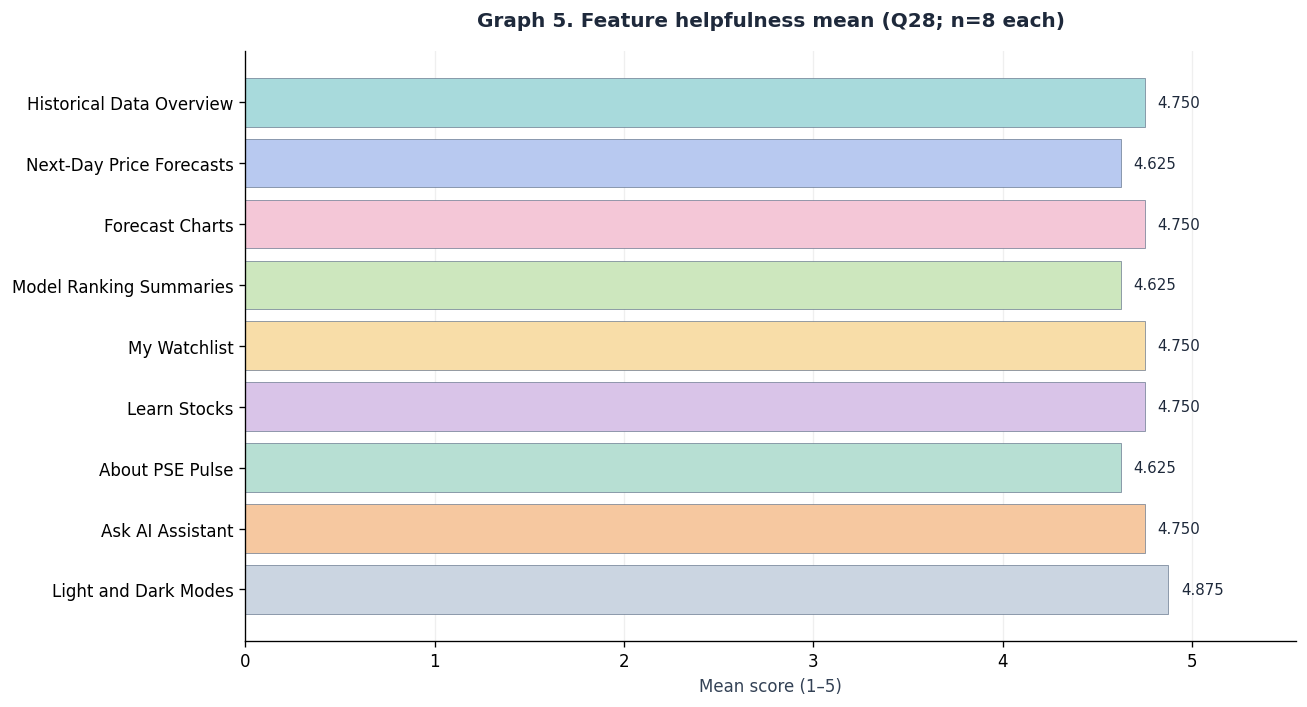

In [11]:
d=tables['uat_feature_helpfulness_summary.csv']; barh(d.item.tolist(),d['mean'].tolist(),'Graph 5. Feature helpfulness mean (Q28; n=8 each)','Mean score (1–5)',5.55,fmt='{:.3f}',height=6)

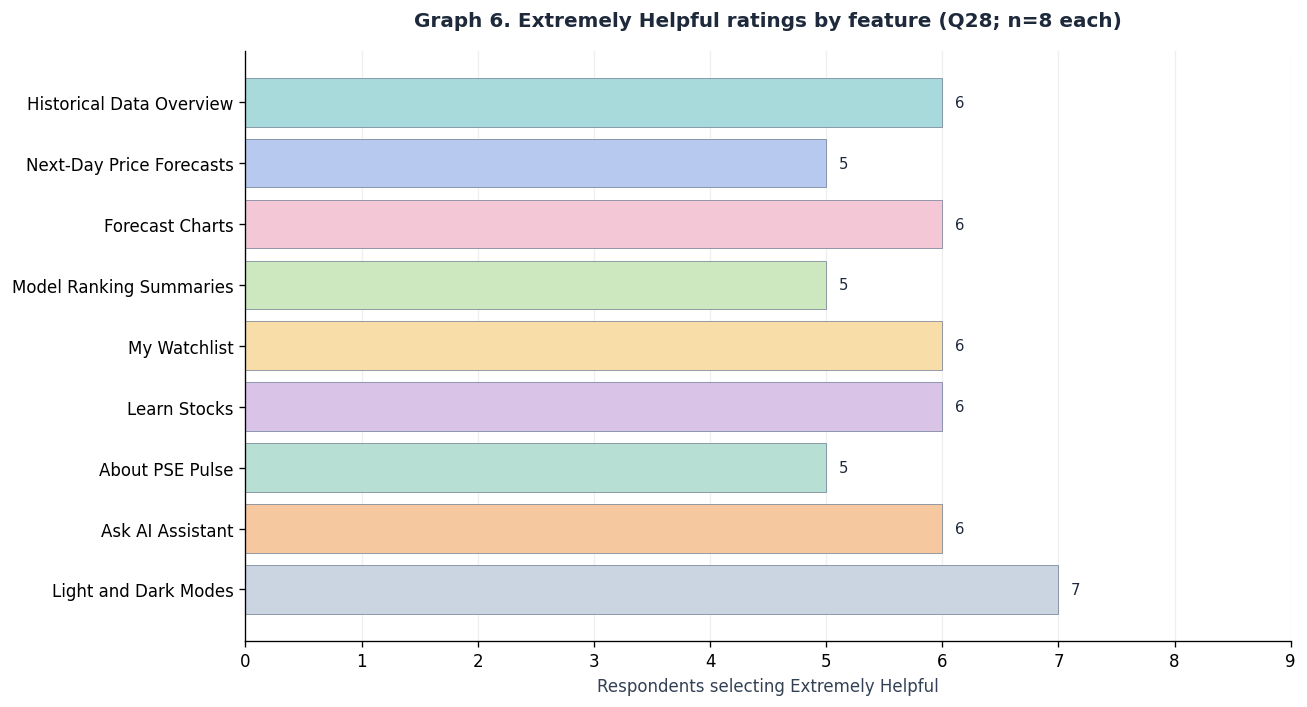

In [12]:
d=tables['uat_feature_helpfulness_summary.csv']; barh(d.item.tolist(),d.score_5_n.tolist(),'Graph 6. Extremely Helpful ratings by feature (Q28; n=8 each)','Respondents selecting Extremely Helpful',9,fmt='{:.0f}',height=6)

**Interpretation.** All nine features received 8/8 Very or Extremely Helpful ratings. Light and Dark Modes had the highest mean (4.875/5; seven Extremely Helpful). Next-Day Price Forecasts, Model Ranking Summaries, and About PSE Pulse had the lowest tied means (4.625/5; five Extremely Helpful each). The differences are descriptive and small.

## 7. Desktop/laptop experience

In [13]:
d=tables['uat_desktop_experience_summary.csv']; show_table(d,['item_id','item','valid_n','score_1_n','score_2_n','score_3_n','score_4_n','score_5_n','mean','median','sample_sd','favorable_pct'])

item_id,item,valid_n,score_1_n,score_2_n,score_3_n,score_4_n,score_5_n,mean,median,sample_sd,favorable_pct
Q29_01,Clean organization,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q29_02,Perceived page speed,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q29_03,Learning use intent,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q29_04,Recommendation intent,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q29_05,Source and freshness visibility,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q29_06,Stock/sector/date controls,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q29_07,Desktop readability,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q29_08,Visual comfort,8,0,0,0,3,5,4.625,5.0,0.518,100.0


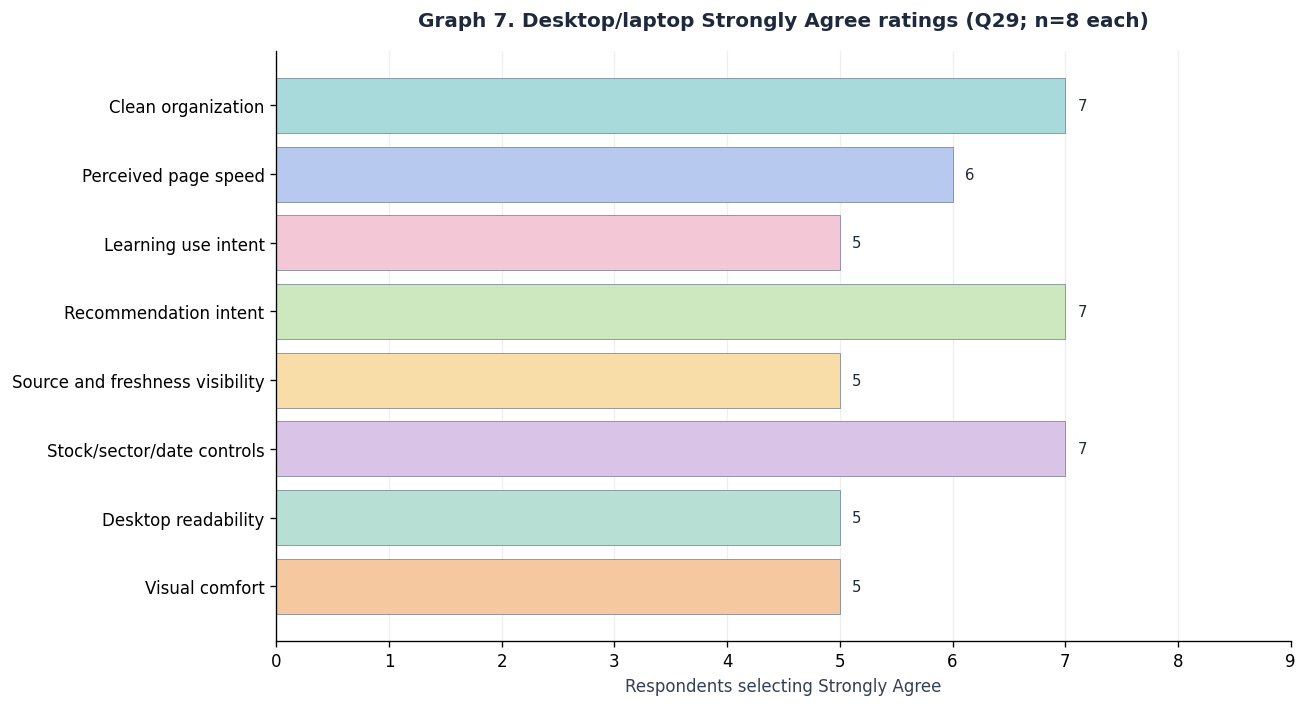

In [14]:
d=tables['uat_desktop_experience_summary.csv']; barh(d.item.tolist(),d.score_5_n.tolist(),'Graph 7. Desktop/laptop Strongly Agree ratings (Q29; n=8 each)','Respondents selecting Strongly Agree',9,fmt='{:.0f}',height=6)

**Interpretation.** All desktop/laptop agreement responses were Agree or Strongly Agree. Learning-use intent, source/freshness visibility, readability, and visual comfort each received five Strongly Agree and three Agree ratings. Perceived loading speed was favorable for all eight, but this is not an objective timing measurement.

## 8. Tablet/mobile experience

In [15]:
d=tables['uat_mobile_experience_summary.csv']; show_table(d,['item_id','item','valid_n','score_1_n','score_2_n','score_3_n','score_4_n','score_5_n','mean','median','sample_sd','favorable_pct'])

item_id,item,valid_n,score_1_n,score_2_n,score_3_n,score_4_n,score_5_n,mean,median,sample_sd,favorable_pct
Q33_01,Mobile navigation,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q33_02,Touch controls,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q33_03,Text readability,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q33_04,Chart readability,8,0,0,0,3,5,4.625,5.0,0.518,100.0
Q33_05,Content access,8,0,0,0,2,6,4.750,5.0,0.463,100.0
Q33_06,Horizontal scrolling,8,0,0,0,5,3,4.375,4.0,0.518,100.0
Q33_07,Company/sector/date controls,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q33_08,Perceived page speed,8,0,0,0,1,7,4.875,5.0,0.354,100.0
Q33_09,Main task completion,8,0,0,0,2,6,4.750,5.0,0.463,100.0


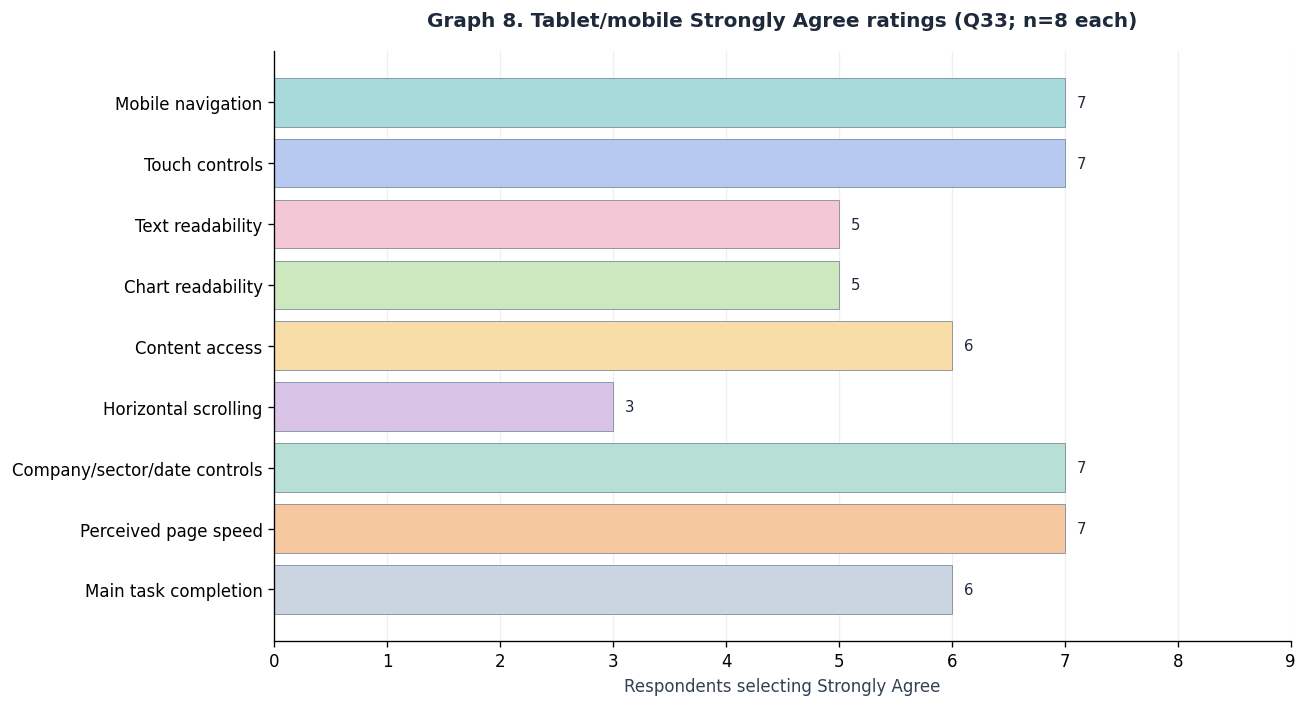

In [16]:
d=tables['uat_mobile_experience_summary.csv']; barh(d.item.tolist(),d.score_5_n.tolist(),'Graph 8. Tablet/mobile Strongly Agree ratings (Q33; n=8 each)','Respondents selecting Strongly Agree',9,fmt='{:.0f}',height=6)

**Interpretation.** All nine mobile items were favorable (8/8 each). Horizontal scrolling had the lowest mean (4.375/5), with three Strongly Agree and five Agree ratings. This suggests the clearest improvement opportunity in the positive response set; it does not show a reported defect.

## 9. Desktop and mobile comparison

The same people evaluated both contexts, but the paired items use different wording and scope. The chart compares related perceptions only; a numerical difference is not a controlled device effect.

In [17]:
show_table(tables['uat_device_comparison.csv'])

related_construct,desktop_item,mobile_item,desktop_valid_n,mobile_valid_n,desktop_favorable_pct,mobile_favorable_pct,desktop_mean,mobile_mean,interpretation
Perceived loading,Q29_02,Q33_08,8,8,100.0,100.0,4.750,4.875,Related but differently worded items; descriptive comparison only
Controls,Q29_06,Q33_07,8,8,100.0,100.0,4.875,4.875,Related but differently worded items; descriptive comparison only
Readability,Q29_07,Q33_03,8,8,100.0,100.0,4.625,4.625,Related but differently worded items; descriptive comparison only
Visual readability,Q29_08,Q33_04,8,8,100.0,100.0,4.625,4.625,Related but differently worded items; descriptive comparison only


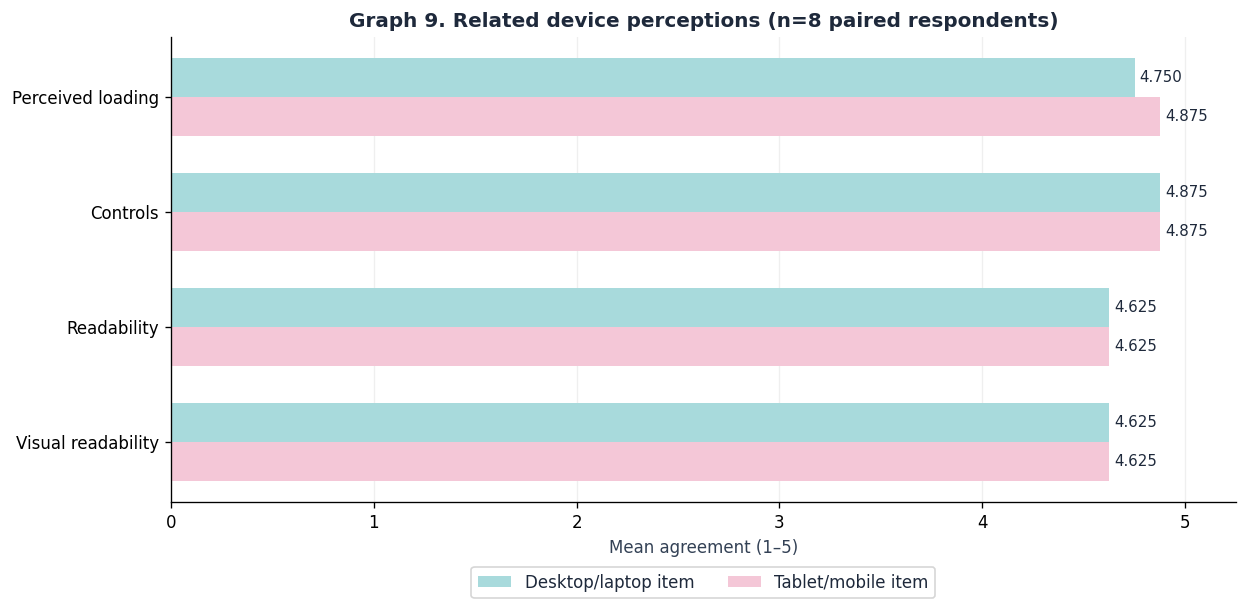

In [18]:
d=tables['uat_device_comparison.csv']; y=np.arange(len(d)); w=.34
fig,ax=plt.subplots(figsize=(10.5,5.2))
ax.barh(y-w/2,d.desktop_mean,w,label='Desktop/laptop item',color=PASTEL[0])
ax.barh(y+w/2,d.mobile_mean,w,label='Tablet/mobile item',color=PASTEL[2])
ax.set_yticks(y,d.related_construct); ax.invert_yaxis(); ax.set_xlim(0,5.25)
ax.set_xlabel('Mean agreement (1–5)'); ax.set_title('Graph 9. Related device perceptions (n=8 paired respondents)')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.12),ncol=2); ax.grid(axis='x',alpha=.2); ax.set_axisbelow(True)
for bars in ax.containers:
    ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=9)
fig.tight_layout(); display(fig); plt.close(fig)

**Interpretation.** Mobile perceived speed and controls scored slightly higher than their desktop-related items. Desktop general readability and mobile text readability have the same mean (4.625/5). These are not identical questions, so the differences should not be interpreted as causal or inferential.

## 10. Requirement-aligned assessment

The requirement definitions below follow the current Capstone 2 Chapter III Requirements Traceability Matrix (Table 9). FR-05 includes company and sector browsing plus sector-peer context. FR-10 concerns comparative model-performance evidence. The classifications describe UAT perception or an applicable rating component; they do not certify complete functional, nonfunctional, or forecasting acceptance. The pooled percentage counts repeated item responses, not independent participants.

In [19]:
show_table(tables['uat_requirement_alignment.csv'])

requirement_id,current_requirement,evidence_items,classification,pooled_item_response_favorable_pct,note
FR-01,"Display ticker, complete company name, and official PSE sector.","Q9,Q10",Partially supported by UAT,100.0,Company finding/selection perceived as easy; correctness for all 15 companies requires functional verification.
FR-02,Display historical OHLCV and volume through readable interactive views.,"Q11,Q28_01",Partially supported by UAT,100.0,Historical context was rated clear/helpful; displayed OHLCV values and ranges require data/output verification.
FR-03,Display next-trading-session forecast and forecast metadata.,Q28_02,Partially supported by UAT,100.0,"Forecast feature rated helpful; target, price, and metadata correctness require output verification."
FR-04,Compare forecasts with corresponding actual closing prices.,"Q12,Q28_03",Partially supported by UAT,100.0,Chart distinction/helpfulness rated; actual/predicted date alignment and accuracy require separate formal and output evidence.
FR-05,Support company and sector browsing and sector-peer context.,"Q9,Q10",Partially supported by UAT,100.0,Company/sector finding and selection rated; approved three-peer membership and comparison behavior not directly evaluated.
FR-06,Provide plain-language educational explanations and definitions.,"Q18,Q25,Q28_06,Q28_08,Q36",Partially supported by UAT,100.0,Explanation clarity/helpfulness rated; coverage and independent comprehension/task success not established.
FR-07,"Display source, freshness, dates, and relevant model/artifact information.","Q8,Q23,Q29_05",Partially supported by UAT,100.0,Source/freshness visibility rated; metadata accuracy and coverage require output verification.
FR-08,"Display uncertainty, limitations, and responsible-use notices.","Q22,Q27",Partially supported by UAT,100.0,Limitation/educational-purpose clarity rated; comprehension and notice coverage on every relevant page not established.
FR-09,"Support appropriate searching, filtering, navigation, and historical-range controls.","Q9,Q10,Q29_06,Q33_07",Partially supported by UAT,100.0,Control ease rated; synchronized behavior and valid displayed information require functional verification.
FR-10,Present comparative model-performance evidence.,"Q21,Q28_04",Partially supported by UAT,100.0,Methods explanation and model-ranking helpfulness rated; displayed metrics and rankings require comparison with approved backend artifacts.


## 11. Qualitative feedback

Themes use documented keyword rules applied to each respondent response; one response can contribute to multiple themes. Counts are distinct respondents per theme. The private text was manually reviewed. No raw quotations are published because the sample is small and free text could be identifying.

In [20]:
show_table(tables['uat_qualitative_themes.csv'])

item_id,theme,respondent_n,denominator,coding_rule
Q34,Ask AI learning support,3,8,"case-insensitive literal/regex terms: ask ai, ai assistant"
Q34,Forecast information,4,8,"case-insensitive literal/regex terms: prediction, forecast, gainer"
Q34,Historical data or charts,4,8,"case-insensitive literal/regex terms: historical, chart, data overview"
Q34,Beginner/Advanced view,1,8,"case-insensitive literal/regex terms: beginner and advanced, mode toggle"
Q35,Optional issue item left blank,8,8,Blank response; does not prove no defects
Q36,Tooltips and terminology,3,8,"case-insensitive literal/regex terms: tooltip, question-mark, acronym, jargon, terms"
Q36,First-time guidance,2,8,"case-insensitive literal/regex terms: walkthrough, guided tour"
Q36,Visual design and chart legend,2,8,"case-insensitive literal/regex terms: color design, color legend"
Q36,No additional change suggested,3,8,"case-insensitive literal/regex terms: ^none, everything already fine, all best for me"


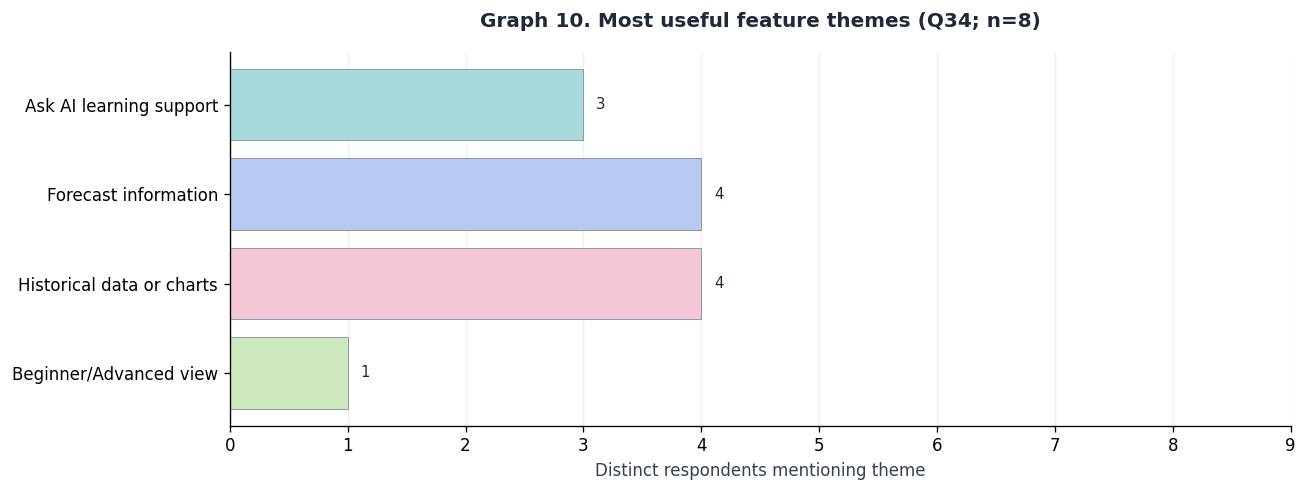

In [21]:
d=tables['uat_qualitative_themes.csv']; d=d[d.item_id=='Q34']; barh(d.theme.tolist(),d.respondent_n.tolist(),'Graph 10. Most useful feature themes (Q34; n=8)','Distinct respondents mentioning theme',9,fmt='{:.0f}')

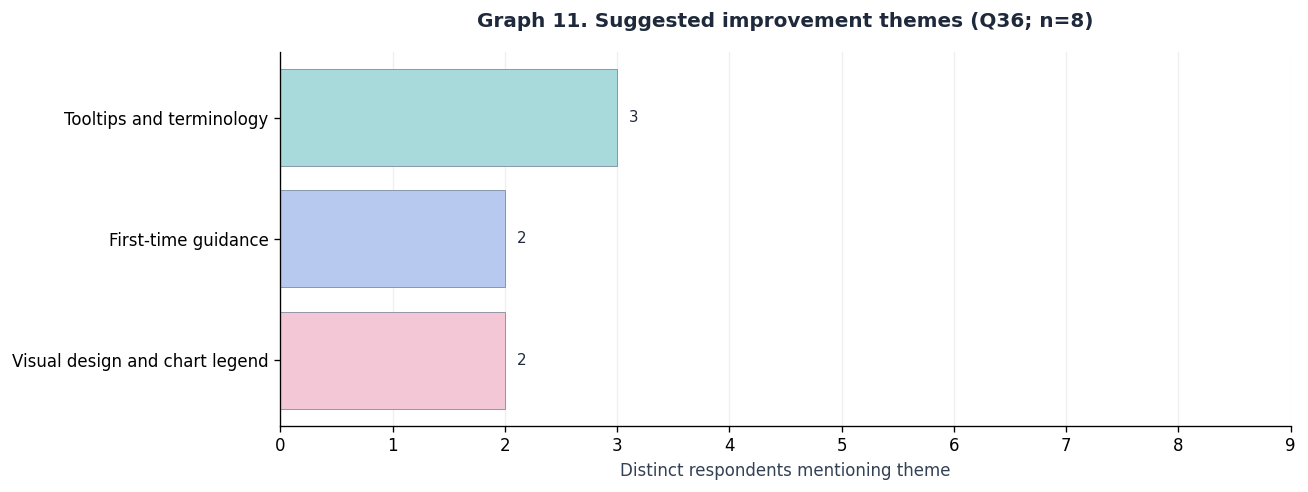

In [22]:
d=tables['uat_qualitative_themes.csv']; d=d[(d.item_id=='Q36') & (d.theme!='No additional change suggested')]; barh(d.theme.tolist(),d.respondent_n.tolist(),'Graph 11. Suggested improvement themes (Q36; n=8)','Distinct respondents mentioning theme',9,fmt='{:.0f}')

**Interpretation.** Forecast information and historical data/charts each appeared in four Q34 responses; Ask AI appeared in three. Three Q36 responses suggested terminology help, two requested first-time guidance, and two mentioned visual design or a chart legend. Q35 was blank for all eight; blank optional answers are not proof that no issues existed.

## 12. Key Chapter IV findings

In [23]:
show_table(tables['uat_chapter4_summary.csv'])

section,items,respondents,valid_item_responses,favorable_item_responses,favorable_item_response_pct,lowest_item_id,lowest_item_mean
Navigation/usability,21,8,168,168,100.0,Q13,4.625
Feature helpfulness,9,8,72,72,100.0,Q28_02,4.625
Desktop/laptop experience,8,8,64,64,100.0,Q29_03,4.625
Tablet/mobile experience,9,8,72,72,100.0,Q33_06,4.375


**Synthesis.** The observed UAT ratings were uniformly favorable: 168/168 navigation, 72/72 feature, 64/64 desktop, and 72/72 mobile item responses scored 4 or 5. This is 376 favorable item responses from eight people, not 376 independent participants. Category distributions still show the relative opportunity to improve horizontal scrolling, first-time guidance, and terminology support.

## 13. Interpretation and research limitations

This is a small researcher-supplied sample of eight, mostly beginners; the workbook cannot prove that they are the same eight people from requirements gathering. Responses are self-reported and repeated within person. The form lacks per-response version metadata, so matching headers and response options do not independently prove each respondent's live form version. No observed unaided core-task completion, direct defect-closure record, objective loading measurement, forecast accuracy calculation, or complete accessibility audit appears in this UAT sheet. Q35 blanks cannot establish defect absence.

The available pre-response research methodology documents an 80% stakeholder acceptance criterion, corresponding to at least seven favorable responses among eight participants. The final UAT ratings satisfy the numerical favorable-response component where applicable. However, formal overall UAT acceptance remains pending verification of the approved criterion's scope, unaided core-task completion, and unresolved Critical/High-severity defect status. Adviser approval timing and a prespecified mapping of the revised questionnaire to designated acceptance items were not independently established. No overall formal PASS is assigned.

## 14. Chapter V evidence

**Conclusion:** Within this eight-person stakeholder sample, respondents rated the tested interface, features, desktop/laptop experience, and tablet/mobile experience favorably. The documented 7-of-8 numerical rating criterion is met where applicable, but overall formal acceptance awaits the other methodological evidence. Positive perceptions do not establish independent external validation, complete functionality, or forecasting accuracy.

**Recommendations:** Prioritize reducing horizontal scrolling on small screens; add short first-time guidance and plain-language tooltips; retain clear data-source, freshness, and responsible-use explanations. Verify task completion, defect closure, technical performance, chart/data correctness, privacy, and responsive behavior using separate evidence.

## 15. Reproducibility and validation

In [24]:
expected = {'navigation':21,'feature':9,'desktop':8,'mobile':9}
for section,count in expected.items():
    key = {'navigation':'uat_navigation_usability_summary.csv','feature':'uat_feature_helpfulness_summary.csv','desktop':'uat_desktop_experience_summary.csv','mobile':'uat_mobile_experience_summary.csv'}[section]
    t=tables[key]
    assert len(t)==count and (t.valid_n+t.missing_n).eq(N).all()
    assert (t[[f'score_{i}_n' for i in range(1,6)]].sum(axis=1)==t.valid_n).all()
    assert (t.favorable_n==t.score_4_n+t.score_5_n).all()
assert sum(tables[k].valid_n.sum() for k in ['uat_navigation_usability_summary.csv','uat_feature_helpfulness_summary.csv','uat_desktop_experience_summary.csv','uat_mobile_experience_summary.csv'])==376
print('Validation passed: 47 mapped rating items; 376 scored responses; category totals and favorable counts reconcile.')

Validation passed: 47 mapped rating items; 376 scored responses; category totals and favorable counts reconcile.


## 16. Source and review note

The original PDF and private workbook were supplied by the researcher. The response sheet is researcher-designated as final; form-version history remains unavailable. The executed notebook and aggregate CSVs provide reviewable evidence. The current requirement definitions follow Capstone 2 Chapter III Table 9. Use the validated notebook tables and aggregate CSVs when revising outdated manuscript Tables 72–77 and related prose.